# RL-16 : Dream-RSI — l'exploration comme code, évaluée off-policy par monde-replay

| | |
|---|---|
| **Série** : Reinforcement Learning | **Prérequis** : [RL-08](RL-08-Dyna-Q-Planification-Python.ipynb) (Dyna-Q), [RL-03](RL-03-Experience-Replay-HER-Python.ipynb) (replay), [RL-13](RL-13-Curiosite-RND-Python.ipynb) (exploration) |
| **Sources** : Zheng et al., *Dream-RSI: Recursive Self-Improvement through Evolving Worlds*, arXiv:2609.14858 | **Genre** : distillation SOTA-Comparison (monde jouet) |

> **Statut de la source.** Preprint cs.CL soumis le 14/09/2026, non relu, 18 auteurs. Ses
> chiffres (162× moins d'appels que SimpleTES sur Lasso, 2.09× sur KernelBench) sont des
> *claims d'auteurs* obtenus avec un agent Gemini-3.1 Pro hors de portée d'un cours. Ce
> notebook reproduit le **mécanisme** — pas les benchmarks — sur un monde jouet exécutable
> en pur C# avec la bibliothèque standard, sans LLM ni GPU.

## L'idée en une table : Dream-RSI est du Dyna transposé aux agents

Le papier revendique lui-même la filiation (*« This idea parallels model-based
reinforcement learning (Sutton, 1990) »*). La table de correspondance s'écrit toute seule :

| Dyna (RL-08, Sutton 1990) | Dream-RSI (ce notebook) |
|---|---|
| modèle appris de l'environnement | arbres de découverte **enregistrés** (les « mondes ») |
| planning : simulations depuis le modèle | dreaming : marches **off-policy** sur les arbres figés |
| amélioration de la politique (Q) | sélection de la **politique d'exploration** |
| boucle act → learn → plan → act | boucle explore → enregistre → rêve → redéploie |

Le point conceptuel fort : dans Dream-RSI, **la politique d'exploration est du code
exécutable** (elle choisit quels nœuds étendre, la largeur des batches, quand s'arrêter),
et ce code peut être **révisé en rêvant** — évalué à coût nul sur l'historique enregistré
avant d'être redéployé en ligne. C'est une boucle d'auto-amélioration récursive (RSI) à la
couche méta-exploration : l'agent qui cherche n'est pas modifié, c'est la façon de chercher
qui évolue.

In [1]:
using System;
using System.Collections.Generic;
using System.Linq;
using System.Globalization;
using System.Text;
using System.Threading;

CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentUICulture = CultureInfo.InvariantCulture;
Thread.CurrentThread.CurrentCulture = CultureInfo.InvariantCulture;
Thread.CurrentThread.CurrentUICulture = CultureInfo.InvariantCulture;

// Le générateur .NET est distinct de celui de Python, même à graine égale.
const int SEED = 42;
// Comparaisons descriptives aux sorties Python citées : ces seuils larges ne
// sont pas des intervalles de confiance. Les régressions C# ci-dessous sont
// contrôlées séparément à la précision des sorties observées.
const double TOL_SCORE_16 = 24.0;
const double TOL_SCORE_48 = 225.6;
const double TOL_EXACT = 1e-9;
// Les références C# seedées sont arrondies à quatre décimales : une demi-unité
// du dernier chiffre affiché, avec une petite marge pour l'arrondi.
const double TOL_REGRESSION_CSHARP = 0.000051;
Console.WriteLine($"seed globale : {SEED}");

seed globale : 42


## 1. Le monde jouet : empilement de cercles (circle packing)

Deux des trois domaines mathématiques du papier (circle packing, autocorrélation) sont
reproductibles avec la seule bibliothèque standard — aucun LLM requis. On prend le
**circle packing** : placer $n$ cercles dans le carré unité en maximisant les distances
par paires.

Le contrat important est le **coût** : appeler `packing_score` = un appel à
l'environnement. C'est l'unité de budget du monde Dream-RSI jouet, exactement comme un
appel d'agent dans le papier.

In [2]:
int N_CIRCLES = 16; // cadran de difficulté du substrat : 16 = régime saturé (ci-dessous),
// 48 = régime dur (section 6 bis) — le plafond du scorer croît comme n(n-1)/2 x 2R
const double R_MAX = 0.10; // rayon « utile » : deux cercles plus proches que 2R se gênent

double dist((double x, double y) a, (double x, double y) b)
{
    double dx = a.x - b.x, dy = a.y - b.y;
    return Math.Sqrt(dx * dx + dy * dy);
}

// Distances saturées et pénalité de chevauchement : une évaluation du score.
double packing_score((double x, double y)[] config)
{
    double s = 0.0;
    for (int i = 0; i < config.Length; i++)
        for (int j = i + 1; j < config.Length; j++)
        {
            double d = dist(config[i], config[j]);
            s += Math.Min(d, 2 * R_MAX);
            if (d < 2 * R_MAX) s -= (2 * R_MAX - d) * 5.0;
        }
    return s;
}

(double x, double y)[] random_config(Random rng)
{
    var config = new (double x, double y)[N_CIRCLES];
    for (int i = 0; i < config.Length; i++)
        config[i] = (rng.NextDouble(), rng.NextDouble());
    return config;
}

// Box-Muller produit les deux déplacements gaussiens du cercle choisi.
(double x, double y)[] mutate((double x, double y)[] config, Random rng, double sigma = 0.15)
{
    var child = ((double x, double y)[])config.Clone();
    int k = rng.Next(child.Length);
    double u1 = 1.0 - rng.NextDouble();
    double u2 = rng.NextDouble();
    double amplitude = Math.Sqrt(-2.0 * Math.Log(u1));
    double angle = 2.0 * Math.PI * u2;
    double x = Math.Min(1.0, Math.Max(0.0, child[k].x + sigma * amplitude * Math.Cos(angle)));
    double y = Math.Min(1.0, Math.Max(0.0, child[k].y + sigma * amplitude * Math.Sin(angle)));
    child[k] = (x, y);
    return child;
}

// Cas déterministes : une paire séparée et une paire confondue.
double scoreSepare = packing_score(new[] { (0.0, 0.0), (1.0, 0.0) });
double scoreConfondu = packing_score(new[] { (0.0, 0.0), (0.0, 0.0) });
if (Math.Abs(scoreSepare - 0.2) > TOL_EXACT || Math.Abs(scoreConfondu + 1.0) > TOL_EXACT)
    throw new Exception("Échec des contrôles déterministes du score.");
double plafond16 = 16 * 15 / 2 * 2 * R_MAX;
double plafond48 = 48 * 47 / 2 * 2 * R_MAX;
if (Math.Abs(plafond16 - 24.0) > TOL_EXACT || Math.Abs(plafond48 - 225.6) > TOL_EXACT)
    throw new Exception("Échec du contrôle des plafonds.");

var config0 = random_config(new Random(SEED));
double scoreInitial = packing_score(config0);
const double referenceInitialePython = 17.1273; // Sortie Python citée, non recalculée ici.
double ecartInitial = scoreInitial - referenceInitialePython;
Console.WriteLine($"score de la configuration initiale : {scoreInitial:F4}");
Console.WriteLine($"Référence Python citée : {referenceInitialePython:F4} ; écart C# − Python : {ecartInitial:+0.0000;-0.0000;0.0000} ; tolérance : {TOL_SCORE_16:F1}");
if (Math.Abs(ecartInitial) > TOL_SCORE_16) throw new Exception("Écart initial hors tolérance.");

score de la configuration initiale : 15.3690


Référence Python citée : 17.1273 ; écart C# − Python : -1.7583 ; tolérance : 24.0


**Lecture chiffrée — le point de départ et son plafond.** La configuration initiale C# atteint **15.3690**, contre **17.1273** pour la référence Python citée, soit un écart de **−1.7583**. Les générateurs sont distincts. Pour 16 cercles, le score est borné par la somme des contributions maximales des paires ; le régime à 48 cercles possède un plafond plus élevé. Les pénalités de chevauchement diminuent le score sous ces plafonds.

## 2. L'arbre de découverte : l'historique comme structure première

Une session de recherche en ligne n'est pas une liste de solutions : c'est un **arbre**.
Chaque nœud porte sa configuration, son observation (le score) et ses enfants — les
candidats effectivement proposés et **payés**. Dans Dream-RSI, cet arbre figé est la
matière première : il devient un « monde » rejouable.

In [3]:
// Un nœud conserve sa configuration, son score et les enfants enregistrés.
class Node
{
    public (double x, double y)[] config;
    public double score;
    public int depth;
    public List<Node> children = new List<Node>();
    public int visits;

    public Node((double x, double y)[] config, double score, int depth = 0)
    {
        this.config = config;
        this.score = score;
        this.depth = depth;
    }
}

// Un appel d'agent enregistre un batch, quelle que soit sa largeur.
List<Node> expand(Node node, Random rng, int batch_size, double sigma = 0.15)
{
    var children = new List<Node>();
    for (int i = 0; i < batch_size; i++)
    {
        var cfg = mutate(node.config, rng, sigma);
        children.Add(new Node(cfg, packing_score(cfg), node.depth + 1));
    }
    node.children = children;
    node.visits++;
    return children;
}

// Le parcours itératif compte la racine et tous ses descendants.
int tree_size(Node root)
{
    int n = 0;
    var stack = new Stack<Node>();
    stack.Push(root);
    while (stack.Count > 0)
    {
        var node = stack.Pop();
        n++;
        foreach (var child in node.children) stack.Push(child);
    }
    return n;
}

// Contrôle indépendant sur un petit arbre connu.
var testRoot = new Node(new[] { (0.0, 0.0), (1.0, 0.0) }, 0.2);
var testChildren = expand(testRoot, new Random(SEED), 4);
if (tree_size(testRoot) != 5 || testChildren.Count != 4 || testRoot.visits != 1 || testChildren.Any(c => c.depth != 1))
    throw new Exception("Échec du contrôle d'expansion de l'arbre.");

## 3. La politique d'exploration est du code

L'agent qui propose des mutations est **inchangé** (fonction `mutate`). Ce qui varie,
c'est la politique qui décide **quel nœud de la frontière étendre** et **avec quelle
largeur** — et cette politique est un objet C# ordinaire : une classe avec une
méthode `select()`. C'est la transposition jouet de « l'exploration explicite et
programmable » du papier : parce que la politique est du code, on peut en générer des
variantes et les comparer.

In [4]:
// Une politique choisit un nœud et fixe la largeur du batch.
interface IPolicy
{
    int batch_size { get; }
    double eps { get; }
    Node select(List<Node> frontier, Random rng);
}

// En cas d'égalité, le premier nœud de la frontière est conservé.
class FixedRefinement : IPolicy
{
    public int batch_size { get; }
    public double eps => 0.0;
    public FixedRefinement(int batch_size = 4) { this.batch_size = batch_size; }
    public Node select(List<Node> frontier, Random rng)
    {
        Node best = frontier[0];
        foreach (var node in frontier)
            if (node.score > best.score) best = node;
        return best;
    }
}

// La diversification choisit uniformément dans la frontière.
class EpsilonGreedy : IPolicy
{
    public double eps { get; }
    public int batch_size { get; }
    public EpsilonGreedy(double eps, int batch_size = 4)
    {
        this.eps = eps;
        this.batch_size = batch_size;
    }
    public Node select(List<Node> frontier, Random rng)
    {
        if (rng.NextDouble() < eps) return frontier[rng.Next(frontier.Count)];
        Node best = frontier[0];
        foreach (var node in frontier)
            if (node.score > best.score) best = node;
        return best;
    }
}

// Parcours de l'arbre complet pour retrouver son meilleur score.
Node tree_best(Node root)
{
    Node best = root;
    var stack = new Stack<Node>();
    stack.Push(root);
    while (stack.Count > 0)
    {
        Node node = stack.Pop();
        if (node.score > best.score) best = node;
        foreach (var child in node.children) stack.Push(child);
    }
    return best;
}

// Une session dépense un batch par expansion et enregistre son monde.
(Node root, double best, List<Node> frontier) run_online(IPolicy policy, Random rng, int n_batches = 30)
{
    var cfg0 = random_config(rng);
    var root = new Node(cfg0, packing_score(cfg0));
    var frontier = new List<Node> { root };
    for (int i = 0; i < n_batches; i++)
    {
        Node node = policy.select(frontier, rng);
        frontier.Remove(node);
        frontier.AddRange(expand(node, rng, policy.batch_size));
    }
    return (root, tree_best(root).score, frontier);
}

## 4. Le replay déterministe : rêver sur l'arbre enregistré

C'est le cœur du papier, et il tient en dix lignes. Évaluer une politique candidate
**sans l'exécuter en ligne** : la faire marcher sur l'arbre enregistré comme elle
l'aurait fait — à chaque nœud, elle choisit parmi les enfants **enregistrés** (ce que
l'agent a déjà payé). Chaque branche existante coûte **zéro** appel d'environnement :
l'évaluation est off-policy sur données historiques, exactement comme l'évaluation
off-policy de RL-09, mais sur un arbre de découverte au lieu d'un buffer de transitions.

Un walker par unité de parallélisme (`batch_size`) ; le score du rêve est le meilleur
score rencontré le long des marches.

In [5]:
// Le replay ne calcule aucun nouveau score : il lit les enfants enregistrés.
(double quality, int steps) replay(Node root, IPolicy policy, Random rng, int max_steps = 30)
{
    double bestOverall = double.NegativeInfinity;
    int stepsMax = 0;
    for (int walker = 0; walker < policy.batch_size; walker++) // un walker par unité de parallélisme
    {
        Node node = root;
        double best = root.score;
        int steps = 0;
        while (node.children.Count > 0 && steps < max_steps)
        {
            node = policy.select(node.children, rng);
            best = Math.Max(best, node.score);
            steps++;
        }
        bestOverall = Math.Max(bestOverall, best);
        stepsMax = Math.Max(stepsMax, steps);
    }
    return (bestOverall, stepsMax);
}

// Régression du protocole .NET seedé : références issues de l'exécution C#,
// arrondies à quatre décimales, et non valeurs Python recalculées.
double[] replayAttenduCSharp = { 22.0425, 19.0951 };
int[] pasAttendusCSharp = { 19, 6 };
const double tolReplayCSharp = 0.00005;
const int tolPasReplay = 30;

// démo : même arbre, deux lectures différentes
var rng_demo = new Random(SEED);
var (root_demo, best_demo, frontier_demo) = run_online(new FixedRefinement(4), rng_demo, 30);
int tailleDemo = tree_size(root_demo);
Console.WriteLine($"arbre enregistré : {tailleDemo} nœuds");
if (tailleDemo != 121) throw new Exception("La taille de l'arbre diffère de 121.");
IPolicy[] politiquesDemo = { new FixedRefinement(4), new EpsilonGreedy(0.3, 8) };
double[] referencesReplayPython = { 22.7717, 20.5466 }; // Sorties Python citées.
int[] referencesPasPython = { 21, 5 }; // Sorties Python citées.
for (int i = 0; i < politiquesDemo.Length; i++)
{
    IPolicy pol = politiquesDemo[i];
    var (q, steps) = replay(root_demo, pol, new Random(7));
    double ecart = q - referencesReplayPython[i];
    int ecartPas = steps - referencesPasPython[i];
    Console.WriteLine($"replay de {pol.GetType().Name}(eps={pol.eps:0.0#}, K={pol.batch_size}) → {q:F4} (marche de {steps} pas, 0 appel payé)");
    Console.WriteLine($"Référence Python citée : {referencesReplayPython[i]:F4}, {referencesPasPython[i]} pas ; écarts C# − Python : {ecart:+0.0000;-0.0000;0.0000}, {ecartPas:+0;-0;0} pas ; tolérances : {TOL_SCORE_16:F1}, {tolPasReplay} pas");
    Console.WriteLine($"Régression C# seedée : attendu {replayAttenduCSharp[i]:F4}, {pasAttendusCSharp[i]} pas ; tolérance score {tolReplayCSharp:F5}, pas exacts");
    if (Math.Abs(q - replayAttenduCSharp[i]) > tolReplayCSharp || steps != pasAttendusCSharp[i])
        throw new Exception("Régression du replay C# seedé.");
    if (Math.Abs(ecart) > TOL_SCORE_16 || Math.Abs(ecartPas) > tolPasReplay)
        throw new Exception("Replay hors tolérance de comparaison.");
    if (steps < 0 || steps > 30 || q < root_demo.score || q > tree_best(root_demo).score + TOL_EXACT)
        throw new Exception("Propriété du replay violée.");
}

arbre enregistré : 121 nœuds


replay de FixedRefinement(eps=0.0, K=4) → 22.0425 (marche de 19 pas, 0 appel payé)


Référence Python citée : 22.7717, 21 pas ; écarts C# − Python : -0.7292, -2 pas ; tolérances : 24.0, 30 pas


Régression C# seedée : attendu 22.0425, 19 pas ; tolérance score 0.00005, pas exacts


replay de EpsilonGreedy(eps=0.3, K=8) → 19.0951 (marche de 6 pas, 0 appel payé)


Référence Python citée : 20.5466, 5 pas ; écarts C# − Python : -1.4515, +1 pas ; tolérances : 24.0, 30 pas


Régression C# seedée : attendu 19.0951, 6 pas ; tolérance score 0.00005, pas exacts


**Lecture chiffrée — l'arbre et ses deux replays gratuits.** Les 30 batches de largeur 4 et la racine donnent **121 nœuds**. Dans cette exécution C#, `FixedRefinement` obtient **22.0425** en **19 pas**, et `EpsilonGreedy` **19.0951** en **6 pas**, sans appel payé. Les références Python citées sont respectivement **22.7717** en 21 pas et **20.5466** en 5 pas : les écarts C# − Python sont **−0.7292**, −2 pas et **−1.4515**, +1 pas. Le replay s'arrête lorsqu'il atteint une feuille enregistrée ou sa limite de pas ; il ne crée pas de branche.

## 5. La fonction de score Eq. 1 : qualité, coût, parallélisme

Le papier classe les politiques candidates par une valeur multi-objectif (Eq. 1) :

$$V = \text{qualité} - \beta_1 \cdot \text{coût} + \beta_2 \cdot \text{parallélisme}$$

- **qualité** : le meilleur score que la politique trouve (ici : son replay sur le pool) ;
- **coût** : le budget qu'elle consommerait en ligne (batches) ;
- **parallélisme** : la largeur de ses batches — un batch large avance plus par appel.

Les deux poids $\beta_1, \beta_2$ sont des leviers pédagogiques : l'**Exercice 2** les
balaye et montre comment le classement du rêve bascule du « cher mais large » au
« économe mais étroit ».

In [6]:
double BETA1 = 0.02; // poids du coût (batches)
double BETA2 = 0.5;  // poids du parallélisme (normalisé par la largeur max de la grille)

// Les poids sont lus à chaque appel pour permettre leur variation.
double value(double quality, int n_batches, int batch_size)
{
    return quality - BETA1 * n_batches + BETA2 * (batch_size / 8.0);
}

// deux politiques de base, même budget en ligne, graines appariées
var (root_a, best_a, frontier_a) = run_online(new FixedRefinement(4), new Random(SEED), 30);
var (root_b, best_b, frontier_b) = run_online(new EpsilonGreedy(0.25, 4), new Random(SEED), 30);
double val_a = value(best_a, 30, 4);
double val_b = value(best_b, 30, 4);
Console.WriteLine($"FixedRefinement(4)    : qualité {best_a:F4} → V = {val_a:F4}");
Console.WriteLine($"EpsilonGreedy(0.25,4) : qualité {best_b:F4} → V = {val_b:F4}");

// Les valeurs Python sont des sorties citées ; les écarts sont calculés ici.
double[] qualitesPython = { 23.0409, 23.3406 };
double[] valeursPython = { 22.6909, 22.9906 };
double[] qualitesCSharp = { best_a, best_b };
double[] valeursCSharp = { val_a, val_b };
for (int i = 0; i < qualitesCSharp.Length; i++)
{
    double ecartQ = qualitesCSharp[i] - qualitesPython[i];
    double ecartV = valeursCSharp[i] - valeursPython[i];
    Console.WriteLine($"Référence Python citée {i + 1} : qualité {qualitesPython[i]:F4}, V {valeursPython[i]:F4} ; écarts C# − Python : {ecartQ:+0.0000;-0.0000;0.0000}, {ecartV:+0.0000;-0.0000;0.0000} ; tolérance {TOL_SCORE_16:F1}");
    if (Math.Abs(ecartQ) > TOL_SCORE_16 || Math.Abs(ecartV) > TOL_SCORE_16)
        throw new Exception("Comparaison à Python hors tolérance.");
    if (Math.Abs((valeursCSharp[i] - qualitesCSharp[i]) - (-0.35)) > TOL_EXACT)
        throw new Exception("Correction Eq. 1 incorrecte.");
}

FixedRefinement(4)    : qualité 23.5425 → V = 23.1925


EpsilonGreedy(0.25,4) : qualité 23.5159 → V = 23.1659


Référence Python citée 1 : qualité 23.0409, V 22.6909 ; écarts C# − Python : +0.5016, +0.5016 ; tolérance 24.0


Référence Python citée 2 : qualité 23.3406, V 22.9906 ; écarts C# − Python : +0.1753, +0.1753 ; tolérance 24.0


**Lecture chiffrée — l'Eq. 1.** Ici, `FixedRefinement(4)` donne une qualité de **23.5425** et V = **23.1925** ; `EpsilonGreedy(0.25,4)` donne **23.5159** et V = **23.1659**. Les références Python citées sont respectivement 23.0409 → 22.6909 et 23.3406 → 22.9906 : les écarts de qualité et de V sont **+0.5016** et **+0.1753**. Avec le même budget et la même largeur, la correction est identique : −0.02 × 30 + 0.5 × 4/8 = **−0.35**. Le classement par V coïncide donc ici avec celui par qualité, mais pas nécessairement lorsque les largeurs diffèrent.

## 6. La boucle RSI miniature : online → monde → rêve → redéploiement

La boucle complète comprend trois étapes :

1. **Online** : l'incumbent dépense son budget et enregistre un arbre qui rejoint le pool.
2. **Rêve** : les candidates sont évaluées par replay sur le pool, sans nouvel appel à l'environnement, et classées par l'Eq. 1.
3. **Sélection avec incumbent** : l'incumbent figure parmi les candidates. Le maximum de **V** sur les évaluations effectuées ne peut donc pas être inférieur à sa valeur évaluée dans ce même classement.

Cette garantie porte sur **V**, pas nécessairement sur la qualité brute : le bonus de largeur peut changer l'ordre. Elle ne garantit pas non plus la performance d'une future session en ligne. Seul le code de la politique évolue ; `mutate` et `packing_score` restent fixes.

In [7]:
int BUDGET = 30; // batches par session en ligne
var GRID = new List<IPolicy>();
foreach (double e in new[] { 0.0, 0.1, 0.3 })
    foreach (int k in new[] { 2, 4, 8 })
        GRID.Add(new EpsilonGreedy(e, k));

// Classement stable par Eq. 1 après replay sur tous les mondes.
List<(double quality, IPolicy policy)> dream(List<Node> worlds, IEnumerable<IPolicy> candidates, Random rng)
{
    var rows = new List<(double quality, IPolicy policy)>();
    foreach (var policy in candidates)
    {
        double quality = worlds.Max(root => replay(root, policy, rng).quality);
        rows.Add((quality, policy));
    }
    return rows.OrderByDescending(row => value(row.quality, BUDGET, row.policy.batch_size)).ToList();
}

IPolicy incumbent = new FixedRefinement(4);
var (root0, best0, frontier0) = run_online(incumbent, new Random(SEED), BUDGET);
var pool = new List<Node> { root0 };
var history = new List<(string step, IPolicy policy, double best)> { ("online 0", incumbent, best0) };
for (int it = 1; it <= 2; it++)
{
    var ranking = dream(pool, GRID.Concat(new[] { incumbent }), new Random(SEED + it));
    IPolicy chosen = ranking[0].policy;
    if (object.ReferenceEquals(chosen, incumbent))
        Console.WriteLine($"itération {it} : le rêve garde l'incumbent ({incumbent.GetType().Name})");
    var (root_new, best_new, frontier_new) = run_online(chosen, new Random(SEED + 100 + it), BUDGET);
    pool.Add(root_new);
    history.Add(($"online {it}", chosen, best_new));
    incumbent = chosen;
}

// Les sorties Python sont citées ; les sessions C# utilisent un générateur distinct.
double[] referenceHistoryPython = { 23.0409, 24.0000, 23.9515 };
Console.WriteLine();
for (int i = 0; i < history.Count; i++)
{
    var h = history[i];
    double ecart = h.best - referenceHistoryPython[i];
    Console.WriteLine($"{h.step} : {h.policy.GetType().Name}(eps={h.policy.eps:F1}, K={h.policy.batch_size}) → qualité en ligne {h.best:F4}");
    Console.WriteLine($"Python cité : {referenceHistoryPython[i]:F4} ; écart C# − Python : {ecart:+0.0000;-0.0000;0.0000} ; tolérance : {TOL_SCORE_16:F1}");
    if (Math.Abs(ecart) > TOL_SCORE_16 || h.best > plafond16 + TOL_EXACT)
        throw new Exception("Trajectoire à 16 cercles hors contrôle.");
}

itération 2 : le rêve garde l'incumbent (EpsilonGreedy)


online 0 : FixedRefinement(eps=0.0, K=4) → qualité en ligne 23.5425


Python cité : 23.0409 ; écart C# − Python : +0.5016 ; tolérance : 24.0


online 1 : EpsilonGreedy(eps=0.0, K=8) → qualité en ligne 24.0000


Python cité : 24.0000 ; écart C# − Python : 0.0000 ; tolérance : 24.0


online 2 : EpsilonGreedy(eps=0.0, K=8) → qualité en ligne 23.9454


Python cité : 23.9515 ; écart C# − Python : -0.0061 ; tolérance : 24.0


**Lecture chiffrée — la trajectoire online.** Les trois sessions C# atteignent **23.5425**, **24.0000** puis **23.9454**. Les références Python citées sont **23.0409**, **24.0000** et **23.9515**, soit des écarts C# − Python de **+0.5016**, **0.0000** et **−0.0061**. La deuxième session atteint le plafond de 24 ; la suivante recule. La sélection garantit le classement de V dans le rêve, pas la performance en ligne d'un nouveau tirage.

In [8]:
// La garantie d'incumbent du papier, vérifiée pas à pas : la sélection est un
// argmax sur un ensemble qui CONTIENT l'incumbent. La valeur V du choix est
// donc supérieure ou égale à celle de l'incumbent dans le même classement.
// Cette garantie ne porte pas nécessairement sur la qualité replay brute.
var checks = new List<(int iteration, string name, double selectedQuality, double incumbentQuality, double selectedValue, double incumbentValue)>();
IPolicy inc = new FixedRefinement(4);
var roots = new List<Node> { run_online(inc, new Random(SEED), BUDGET).root };
double[] referenceReplayChecksPython = { 22.7717, 23.9677 }; // Références Python citées.
for (int it = 1; it <= 2; it++)
{
    var rankingCheck = dream(roots, GRID.Concat(new[] { inc }), new Random(SEED + it));
    var selected = rankingCheck[0];
    var incumbentRow = rankingCheck.First(row => object.ReferenceEquals(row.policy, inc));
    double vSelected = value(selected.quality, BUDGET, selected.policy.batch_size);
    double vIncumbent = value(incumbentRow.quality, BUDGET, inc.batch_size);
    checks.Add((it, selected.policy.GetType().Name, selected.quality, incumbentRow.quality, vSelected, vIncumbent));
    if (vSelected + TOL_EXACT < vIncumbent) throw new Exception("Régression du classement V.");
    roots.Add(run_online(selected.policy, new Random(SEED + 100 + it), BUDGET).root);
    inc = selected.policy;
}
foreach (var check in checks)
{
    bool qualiteNonRegresse = check.selectedQuality >= check.incumbentQuality;
    bool valeurNonRegresse = check.selectedValue + TOL_EXACT >= check.incumbentValue;
    double ecart = check.selectedQuality - referenceReplayChecksPython[check.iteration - 1];
    Console.WriteLine($"itération {check.iteration} : choisi {check.name} — replay {check.selectedQuality:F4} vs incumbent {check.incumbentQuality:F4} → non-régression qualité {(qualiteNonRegresse ? "VRAIE" : "FAUSSE")}");
    Console.WriteLine($"V choisi {check.selectedValue:F4} vs incumbent {check.incumbentValue:F4} → non-régression classement {(valeurNonRegresse ? "VRAIE" : "FAUSSE")}");
    Console.WriteLine($"Replay Python cité : {referenceReplayChecksPython[check.iteration - 1]:F4} ; écart C# − Python : {ecart:+0.0000;-0.0000;0.0000} ; tolérance : {TOL_SCORE_16:F1}");
    if (Math.Abs(ecart) > TOL_SCORE_16) throw new Exception("Replay hors tolérance.");
}

itération 1 : choisi EpsilonGreedy — replay 22.0425 vs incumbent 22.0425 → non-régression qualité VRAIE


V choisi 21.9425 vs incumbent 21.6925 → non-régression classement VRAIE


Replay Python cité : 22.7717 ; écart C# − Python : -0.7292 ; tolérance : 24.0


itération 2 : choisi EpsilonGreedy — replay 23.1081 vs incumbent 23.1081 → non-régression qualité VRAIE


V choisi 23.0081 vs incumbent 23.0081 → non-régression classement VRAIE


Replay Python cité : 23.9677 ; écart C# − Python : -0.8596 ; tolérance : 24.0


### Lecture du résultat (les chiffres ci-dessus sont ceux de l'exécution)

À l'itération 1, la qualité replay du choix et celle de l'incumbent sont toutes deux **22.0425** ; leurs valeurs V sont respectivement **21.9425** et **21.6925**. Le bonus de largeur départage ici les qualités égales. La qualité replay Python citée est **22.7717**, soit un écart C# − Python de **−0.7292**.

À l'itération 2, les qualités replay sont toutes deux **23.1081** et les valeurs V toutes deux **23.0081** ; l'incumbent est conservé. La référence Python citée est **23.9677**, soit un écart de **−0.8596**.

Dans ces deux cas la qualité brute observée ne régresse pas, mais seule la non-régression de **V sur les évaluations du classement** découle de la présence de l'incumbent. La session en ligne suivante peut néanmoins varier : ici, elle passe de 24.0000 à 23.9454.

### Le cadran de difficulté : le même mécanisme sur un monde qui ne sature pas

Le régime à 16 cercles atteint le plafond du scorer (24.0) dès la première session du
nouveau policy : passé ce point, la boucle RSI n'a plus rien à départager — c'est le
**substrat**, pas le mécanisme, qui l'endort. Le test décisif : rejouer le même
protocole (mêmes graines, même budget, même grille) sur un monde plus dur — **48
cercles** au lieu de 16. Le plafond passe à 48 × 47 / 2 × 0.2 = **225.6** ; une
session de 30 batches ne l'atteint plus, et la recherche a de la marge pour vivre.
Cinq itérations au lieu de deux, pour laisser le cadran s'exprimer — tout le reste
est inchangé.

In [9]:
// Régression des résultats C# seedés des sections précédentes. Les références
// sont les sorties C# à quatre décimales, pas des tirages Python recalculés.
void verifierRegression(string nom, double observe, double attendu)
{
    double ecart = observe - attendu;
    Console.WriteLine($"Régression C# {nom} : calculé {observe:F4}, attendu {attendu:F4}, écart {ecart:+0.00000;-0.00000;0.00000}, tolérance {TOL_REGRESSION_CSHARP:F6}");
    if (Math.Abs(ecart) > TOL_REGRESSION_CSHARP)
        throw new Exception($"Régression C# : {nom}.");
}
verifierRegression("score initial", scoreInitial, 15.3690);
verifierRegression("qualité FixedRefinement", best_a, 23.5425);
verifierRegression("valeur FixedRefinement", val_a, 23.1925);
verifierRegression("qualité EpsilonGreedy", best_b, 23.5159);
verifierRegression("valeur EpsilonGreedy", val_b, 23.1659);
double[] attenduHistoryCSharp = { 23.5425, 24.0000, 23.9454 };
for (int i = 0; i < history.Count; i++)
    verifierRegression($"online {i}", history[i].best, attenduHistoryCSharp[i]);
double[] attenduReplayChecksCSharp = { 22.0425, 23.1081 };
double[] attenduVChoisiCSharp = { 21.9425, 23.0081 };
double[] attenduVIncumbentCSharp = { 21.6925, 23.0081 };
for (int i = 0; i < checks.Count; i++)
{
    verifierRegression($"replay choisi {i + 1}", checks[i].selectedQuality, attenduReplayChecksCSharp[i]);
    verifierRegression($"replay incumbent {i + 1}", checks[i].incumbentQuality, attenduReplayChecksCSharp[i]);
    verifierRegression($"V choisi {i + 1}", checks[i].selectedValue, attenduVChoisiCSharp[i]);
    verifierRegression($"V incumbent {i + 1}", checks[i].incumbentValue, attenduVIncumbentCSharp[i]);
}

N_CIRCLES = 48; // régime dur — le reste du protocole est inchangé
double CEIL_B = 48 * 47 / 2 * 2 * R_MAX; // plafond du scorer à 48 cercles : 225.6
if (Math.Abs(CEIL_B - 225.6) > TOL_EXACT) throw new Exception("Plafond incorrect.");

// Seuil descriptif : deux changements d'écart sur cinq itérations permettent
// des trajectoires distinctes sans accepter tous les comptes possibles. Ce
// seuil n'est pas un intervalle de confiance ; la régression C# est exacte.
const int referenceSwitchesPython = 2; // Sortie Python citée.
const int tolSwitches = 2;
const int attenduSwitchesCSharp = 1;
double[] attenduHardCSharp = { 195.8922, 200.6600, 202.1176, 199.0430, 200.0820, 203.3601 };

IPolicy incumbent_b = new FixedRefinement(4);
var (root_b0, best_b0, frontier_b0) = run_online(incumbent_b, new Random(SEED), BUDGET);
var pool_b = new List<Node> { root_b0 };
var history_b = new List<(string step, string policy, double best)> { ("online 0", incumbent_b.GetType().Name, best_b0) };
int switches_b = 0;
for (int it = 1; it <= 5; it++)
{
    var ranking_b = dream(pool_b, GRID.Concat(new[] { incumbent_b }), new Random(SEED + it));
    IPolicy chosen_b = ranking_b[0].policy;
    if (!object.ReferenceEquals(chosen_b, incumbent_b)) switches_b++;
    incumbent_b = chosen_b;
    var (root_bn, best_bn, frontier_bn) = run_online(incumbent_b, new Random(SEED + 100 + it), BUDGET);
    pool_b.Add(root_bn);
    history_b.Add(($"online {it}", $"{incumbent_b.GetType().Name}(eps={incumbent_b.eps:F1},K={incumbent_b.batch_size})", best_bn));
}

// Valeurs issues de la sortie Python, citées et non recalculées.
double[] referenceHardPython = { 197.2511, 199.5677, 193.8576, 201.7292, 203.5800, 200.0272 };
for (int i = 0; i < history_b.Count; i++)
{
    var h = history_b[i];
    double ecart = h.best - referenceHardPython[i];
    Console.WriteLine($"{h.step} : {h.policy} → qualité en ligne {h.best:F4} ({100 * h.best / CEIL_B:F1}% du plafond)");
    Console.WriteLine($"Python cité : {referenceHardPython[i]:F4} ; écart C# − Python : {ecart:+0.0000;-0.0000;0.0000} ; tolérance : {TOL_SCORE_48:F1}");
    if (Math.Abs(ecart) > TOL_SCORE_48 || h.best > CEIL_B + TOL_EXACT)
        throw new Exception("Trajectoire dure hors contrôle.");
    verifierRegression($"régime dur online {i}", h.best, attenduHardCSharp[i]);
}
Console.WriteLine($"switches d'incumbent sur 5 itérations : {switches_b}");
Console.WriteLine($"Python cité : {referenceSwitchesPython} ; écart C# − Python : {switches_b - referenceSwitchesPython:+0;-0;0} ; tolérance : {tolSwitches}");
Console.WriteLine($"Régression C# seedée : attendu {attenduSwitchesCSharp}, écart {switches_b - attenduSwitchesCSharp:+0;-0;0}, tolérance 0");
if (Math.Abs(switches_b - referenceSwitchesPython) > tolSwitches || switches_b != attenduSwitchesCSharp)
    throw new Exception("Nombre de changements hors contrôle.");
N_CIRCLES = 16; // retour au régime du carnet pour la suite

Régression C# score initial : calculé 15.3690, attendu 15.3690, écart 0.00000, tolérance 0.000051


Régression C# qualité FixedRefinement : calculé 23.5425, attendu 23.5425, écart -0.00004, tolérance 0.000051


Régression C# valeur FixedRefinement : calculé 23.1925, attendu 23.1925, écart -0.00004, tolérance 0.000051


Régression C# qualité EpsilonGreedy : calculé 23.5159, attendu 23.5159, écart -0.00004, tolérance 0.000051


Régression C# valeur EpsilonGreedy : calculé 23.1659, attendu 23.1659, écart -0.00004, tolérance 0.000051


Régression C# online 0 : calculé 23.5425, attendu 23.5425, écart -0.00004, tolérance 0.000051


... (27 outputs left out)

Régression C# régime dur online 5 : calculé 203.3601, attendu 203.3601, écart -0.00001, tolérance 0.000051


switches d'incumbent sur 5 itérations : 1


Python cité : 2 ; écart C# − Python : -1 ; tolérance : 2


Régression C# seedée : attendu 1, écart 0, tolérance 0


**Lecture chiffrée — le cadran de difficulté.** Dans cette exécution C#, le départ à 48 cercles atteint `195.8922`, soit `86.8%` du plafond de 225.6. La trajectoire culmine à `203.3601` (`90.1%`) à `online 5`, et l'incumbent change une fois en cinq itérations. La source Python citée démarre à `197.2511` et compte deux changements ; son maximum intervient à une autre étape. Ces écarts accompagnent les tirages d'un générateur différent.

À 16 cercles, une session en ligne atteint le plafond ; à 48 cercles, aucune des sessions affichées ne l'atteint. Le régime dur laisse donc davantage de marge sous le plafond, sans garantir à lui seul que chaque nouvelle session améliore la précédente.

## 7. L'ablation §5.1 : guidance par résumé ou replay brut ?

L'ablation la plus contre-intuitive du papier (§5.1) rapporte que remplacer le replay brut par une **guidance sémantique** — un résumé de l'historique injecté dans le choix — *sous-performe systématiquement* dans les tâches étudiées. Selon cette lecture, la guidance sur-contraint l'espace : le résumé perd la structure fine de l'arbre que le replay exploite.

La version jouet : la « guidance » est une **règle écrite à la main** qui lit un résumé statistique du monde (l'écart-type des scores enregistrés) et en déduit une politique, sans jamais rejouer l'arbre. On la confronte au choix par replay sur la même grille, et on mesure **honnêtement** ce que chaque choix rapporte sur des sessions en ligne fraîches (graines appariées). Les résultats ci-dessous permettent d'examiner cette comparaison sans présumer qu'elle reproduit la direction rapportée par le papier.

In [10]:
// La guidance remplace le replay par une règle sur l'écart-type des scores.
IPolicy guided_choice(List<Node> worlds)
{
    var scores = worlds.SelectMany(r => r.children).Select(c => c.score).ToList();
    double mean = scores.Average();
    double spread = Math.Sqrt(scores.Average(s => (s - mean) * (s - mean)));
    if (spread > 0.8) // « monde hétérogène → diversifier » (règle inventée)
        return new EpsilonGreedy(0.3, 8);
    return new EpsilonGreedy(0.0, 8); // « monde homogène → raffiner »
}

// Comparaison descriptive entre générateurs distincts : trois essais sur douze
// et 0.25 point de marge autorisent des fluctuations sans couvrir tout résultat.
// Ces seuils pédagogiques ne sont pas des intervalles de confiance statistiques.
const int tolComptes = 3;
const double tolMarges16 = 0.25;
// Régression du protocole .NET seedé : sorties C# observées à quatre décimales.
const double tolRegressionAblation = 0.00005;
int[] attenduComptes16 = { 1, 3, 8 };
double[] attenduMarges16 = { -0.2862, 0.0680 };

int N_TRIALS = 12;
int replay_wins = 0, guided_wins = 0, ties = 0;
var margins = new List<double>();
for (int t = 0; t < N_TRIALS; t++)
{
    var world = new List<Node> { run_online(new FixedRefinement(4), new Random(2000 + t), BUDGET).root };
    IPolicy pol_r = dream(world, GRID, new Random(3000 + t))[0].policy; // choix par replay
    IPolicy pol_g = guided_choice(world); // choix par guidance
    double q_r = run_online(pol_r, new Random(4000 + t), BUDGET).best; // graines appariées
    double q_g = run_online(pol_g, new Random(4000 + t), BUDGET).best;
    margins.Add(q_r - q_g);
    if (q_r > q_g) replay_wins++;
    else if (q_g > q_r) guided_wins++;
    else ties++;
}
Console.WriteLine($"sur {N_TRIALS} mondes jouets : replay brut {replay_wins} victoires | guidance sémantique {guided_wins} | égalités {ties}");
Console.WriteLine($"marge q_replay − q_guidance : [{margins.Min():F4}, {margins.Max():F4}]");
int[] comptes = { replay_wins, guided_wins, ties };
int[] comptesPython = { 3, 2, 7 }; // Sorties Python citées.
double[] margesPython = { -0.2021, 0.2404 }; // Sorties Python citées.
double[] margesObservees = { margins.Min(), margins.Max() };
for (int i = 0; i < comptes.Length; i++)
{
    int ecart = comptes[i] - comptesPython[i];
    Console.WriteLine($"Compte {i + 1} : Python cité {comptesPython[i]}, écart C# − Python {ecart:+0;-0;0}, tolérance {tolComptes} ; régression C# attendue {attenduComptes16[i]}");
    if (Math.Abs(ecart) > tolComptes || comptes[i] != attenduComptes16[i])
        throw new Exception("Compte d'ablation hors contrôle.");
}
for (int i = 0; i < margesObservees.Length; i++)
{
    double ecart = margesObservees[i] - margesPython[i];
    Console.WriteLine($"Marge {i + 1} : Python cité {margesPython[i]:F4}, écart C# − Python {ecart:+0.0000;-0.0000;0.0000}, tolérance {tolMarges16:F2} ; régression C# attendue {attenduMarges16[i]:F4}, tolérance {tolRegressionAblation:F5}");
    if (Math.Abs(ecart) > tolMarges16 || Math.Abs(margesObservees[i] - attenduMarges16[i]) > tolRegressionAblation)
        throw new Exception("Marge d'ablation hors contrôle.");
}
if (replay_wins + guided_wins + ties != N_TRIALS) throw new Exception("Décompte incohérent.");

sur 12 mondes jouets : replay brut 1 victoires | guidance sémantique 3 | égalités 8


marge q_replay − q_guidance : [-0.2862, 0.0680]


Compte 1 : Python cité 3, écart C# − Python -2, tolérance 3 ; régression C# attendue 1


Compte 2 : Python cité 2, écart C# − Python +1, tolérance 3 ; régression C# attendue 3


Compte 3 : Python cité 7, écart C# − Python +1, tolérance 3 ; régression C# attendue 8


Marge 1 : Python cité -0.2021, écart C# − Python -0.0841, tolérance 0.25 ; régression C# attendue -0.2862, tolérance 0.00005


Marge 2 : Python cité 0.2404, écart C# − Python -0.1724, tolérance 0.25 ; régression C# attendue 0.0680, tolérance 0.00005


### Lecture de l'ablation (chiffres de l'exécution ci-dessus)

À 16 cercles, cette exécution C# donne **1 victoire du replay, 3 de la guidance et 8 égalités**, avec des marges de **−0.2862 à +0.0680**. La référence Python citée donne **3 / 2 / 7** et **[−0.2021, +0.2404]** : les écarts C# − Python sont **−2 / +1 / +1** pour les comptes et **−0.0841 / −0.1724** pour les bornes. Les marges traversent zéro ; ces 12 essais ne permettent pas de conclure à une supériorité générale.

Le papier étudie huit tâches réelles avec un agent LLM et des résumés sémantiques. Ici, la guidance est une règle jouet : cette ablation ne prouve pas l'effet à cette échelle.

In [11]:
// La même ablation sur le régime dur : 48 cercles, plafond 225.6 hors de portée
// d'une session — les deux choix ne sont plus garantis de converger. Protocole
// inchangé (12 mondes, graines appariées, même budget).
// Seuils descriptifs entre RNG distincts : cinq essais sur douze et huit points
// de marge ; ils ne constituent pas des intervalles de confiance statistiques.
const int tolComptes48 = 5;
const double tolMarges48 = 8.0;
// Régression .NET seedée, valeurs observées à quatre décimales ; la tolérance
// tolRegressionAblation de la cellule précédente couvre leur arrondi.
int[] attenduComptes48 = { 4, 3, 5 };
double[] attenduMarges48 = { -7.3308, 4.1705 };
N_CIRCLES = 48;
N_TRIALS = 12;
int replay_wins_b = 0, guided_wins_b = 0, ties_b = 0;
var margins_b = new List<double>();
for (int t = 0; t < N_TRIALS; t++)
{
    var world_b = new List<Node> { run_online(new FixedRefinement(4), new Random(2000 + t), BUDGET).root };
    IPolicy pol_rb = dream(world_b, GRID, new Random(3000 + t))[0].policy; // choix par replay
    IPolicy pol_gb = guided_choice(world_b); // choix par guidance
    double q_rb = run_online(pol_rb, new Random(4000 + t), BUDGET).best; // graines appariées
    double q_gb = run_online(pol_gb, new Random(4000 + t), BUDGET).best;
    margins_b.Add(q_rb - q_gb);
    if (q_rb > q_gb) replay_wins_b++;
    else if (q_gb > q_rb) guided_wins_b++;
    else ties_b++;
}
Console.WriteLine($"sur {N_TRIALS} mondes durs : replay brut {replay_wins_b} victoires | guidance sémantique {guided_wins_b} | égalités {ties_b}");
Console.WriteLine($"marge q_replay − q_guidance : [{margins_b.Min():F4}, {margins_b.Max():F4}]");
int[] comptes_b = { replay_wins_b, guided_wins_b, ties_b };
int[] comptesPython_b = { 8, 0, 4 }; // Sorties Python citées.
double[] margesPython_b = { 0.0000, 4.4131 }; // Sorties Python citées.
double[] margesObservees_b = { margins_b.Min(), margins_b.Max() };
for (int i = 0; i < comptes_b.Length; i++)
{
    int ecart = comptes_b[i] - comptesPython_b[i];
    Console.WriteLine($"Compte {i + 1} : Python cité {comptesPython_b[i]}, écart C# − Python {ecart:+0;-0;0}, tolérance {tolComptes48} ; régression C# attendue {attenduComptes48[i]}");
    if (Math.Abs(ecart) > tolComptes48 || comptes_b[i] != attenduComptes48[i])
        throw new Exception("Compte d'ablation dure hors contrôle.");
}
for (int i = 0; i < margesObservees_b.Length; i++)
{
    double ecart = margesObservees_b[i] - margesPython_b[i];
    Console.WriteLine($"Marge {i + 1} : Python cité {margesPython_b[i]:F4}, écart C# − Python {ecart:+0.0000;-0.0000;0.0000}, tolérance {tolMarges48:F1} ; régression C# attendue {attenduMarges48[i]:F4}, tolérance {tolRegressionAblation:F5}");
    if (Math.Abs(ecart) > tolMarges48 || Math.Abs(margesObservees_b[i] - attenduMarges48[i]) > tolRegressionAblation)
        throw new Exception("Marge d'ablation dure hors contrôle.");
}
if (replay_wins_b + guided_wins_b + ties_b != N_TRIALS) throw new Exception("Décompte incohérent.");
N_CIRCLES = 16; // retour au régime du carnet pour la suite

sur 12 mondes durs : replay brut 4 victoires | guidance sémantique 3 | égalités 5


marge q_replay − q_guidance : [-7.3308, 4.1705]


Compte 1 : Python cité 8, écart C# − Python -4, tolérance 5 ; régression C# attendue 4


Compte 2 : Python cité 0, écart C# − Python +3, tolérance 5 ; régression C# attendue 3


Compte 3 : Python cité 4, écart C# − Python +1, tolérance 5 ; régression C# attendue 5


Marge 1 : Python cité 0.0000, écart C# − Python -7.3308, tolérance 8.0 ; régression C# attendue -7.3308, tolérance 0.00005


Marge 2 : Python cité 4.4131, écart C# − Python -0.2426, tolérance 8.0 ; régression C# attendue 4.1705, tolérance 0.00005


**Lecture chiffrée — les deux régimes.** À 48 cercles, le C# donne **4 victoires du replay, 3 de la guidance et 5 égalités**, avec une marge entre **−7.3308 et +4.1705**. La référence Python citée donne **8 / 0 / 4**, avec **[0.0000, 4.4131]**. Les écarts C# − Python sont donc **−4 / +3 / +1** pour les comptes et **−7.3308 / −0.2426** pour les bornes.

À 16 cercles, les comptes C# sont **1 / 3 / 8**, avec des marges **[−0.2862, +0.0680]**. Dans les deux régimes C#, les marges traversent zéro. Le régime dur rend des écarts plus visibles, mais cette expérience ne montre pas une victoire systématique du replay.

## 8. Ce que le jouet ne montre pas — limites assumées

1. **La garantie d'incumbent porte sur V dans le classement du rêve**, pas nécessairement sur la qualité brute ni sur la performance future en ligne. Ici, la qualité brute ne régresse pas dans les deux comparaisons observées ; la session en ligne passe pourtant de 24.00 à 23.95.
2. **Les chiffres du papier ne sont pas reproduits** : Lasso 3587→2931 ms en 317 appels, 162× moins de générations que SimpleTES, KernelBench ×2.09 exigent Gemini-3.1 Pro et des budgets disymétriques.
3. **Preprint non relu** : les comparaisons SimpleTES/AlphaEvolve se citent avec leurs conditions d'expérience.
4. **L'agent du jouet ne propose pas du code** : `mutate` est un opérateur fixe. L'invariant conservé est que l'agent ne change pas tandis que la politique change.

Table des centres : indice | x | y


0 | 1.00000000 | 0.00000000


1 | 0.42229332 | 0.29394320


2 | 0.00000000 | 0.38480052


3 | 0.42619152 | 0.68473188


4 | 0.79275461 | 0.37386252


... (11 outputs left out)

Table de la trajectoire : étape | qualité


online 0 | 23.54246020


online 1 | 24.00000000


online 2 | 23.94541389


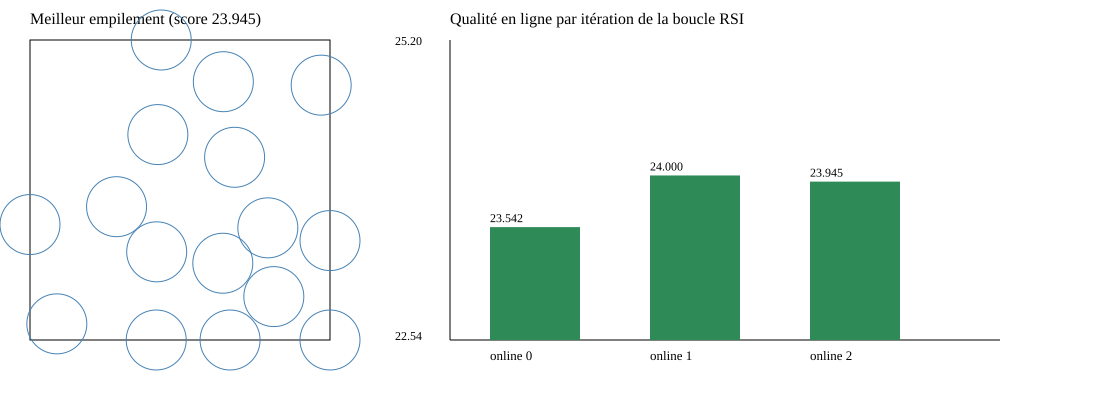

In [12]:
// Figure de synthèse : le meilleur empilement trouvé + la trajectoire de la boucle RSI
var bnode = tree_best(pool[pool.Count - 1]);
Console.WriteLine("Table des centres : indice | x | y");
for (int i = 0; i < bnode.config.Length; i++)
    Console.WriteLine($"{i} | {bnode.config[i].x:F8} | {bnode.config[i].y:F8}");
Console.WriteLine("Table de la trajectoire : étape | qualité");
foreach (var h in history) Console.WriteLine($"{h.step} | {h.best:F8}");
if (bnode.config.Length != 16 || Math.Abs(packing_score(bnode.config) - bnode.score) > TOL_EXACT)
    throw new Exception("Configuration de la figure incohérente.");

var svg = new StringBuilder();
svg.Append("<svg xmlns='http://www.w3.org/2000/svg' width='1100' height='400' viewBox='0 0 1100 400'>");
svg.Append("<rect width='1100' height='400' fill='white'/>");
svg.Append($"<text x='30' y='24' font-size='16'>Meilleur empilement (score {bnode.score:F3})</text>");
svg.Append("<rect x='30' y='40' width='300' height='300' fill='none' stroke='black'/>");
foreach (var p in bnode.config)
    svg.Append($"<circle cx='{30 + 300 * p.x:F4}' cy='{340 - 300 * p.y:F4}' r='{300 * R_MAX:F4}' fill='none' stroke='steelblue'/>");
svg.Append("<text x='450' y='24' font-size='16'>Qualité en ligne par itération de la boucle RSI</text>");
double yMin = history.Min(h => h.best) - 1.0;
double yMax = history.Max(h => h.best) * 1.05;
svg.Append("<line x1='450' y1='340' x2='1000' y2='340' stroke='black'/>");
svg.Append("<line x1='450' y1='40' x2='450' y2='340' stroke='black'/>");
for (int i = 0; i < history.Count; i++)
{
    double height = 300.0 * (history[i].best - yMin) / (yMax - yMin);
    double x = 490 + i * 160;
    svg.Append($"<rect x='{x:F2}' y='{340 - height:F2}' width='90' height='{height:F2}' fill='seagreen'/>");
    svg.Append($"<text x='{x:F2}' y='360' font-size='13'>{history[i].step}</text>");
    svg.Append($"<text x='{x:F2}' y='{335 - height:F2}' font-size='12'>{history[i].best:F3}</text>");
}
svg.Append($"<text x='395' y='45' font-size='12'>{yMax:F2}</text><text x='395' y='340' font-size='12'>{yMin:F2}</text>");
svg.Append("</svg>");

// Un type dédié évite le formateur texte brut utilisé pour les chaînes.
class GraphiqueRsi
{
    public string Svg { get; }
    public GraphiqueRsi(string svg) { Svg = svg; }
}
Microsoft.DotNet.Interactive.Formatting.Formatter.Register<GraphiqueRsi>(
    (graphique, writer) => writer.Write(graphique.Svg), "image/svg+xml");
Microsoft.DotNet.Interactive.Formatting.Formatter.SetPreferredMimeTypesFor(
    typeof(GraphiqueRsi), "image/svg+xml");
display(new GraphiqueRsi(svg.ToString()));

**Lecture de la figure de synthèse.** À gauche, l'empilement du dernier monde C# a un score de **23.945** : il ne sature pas le plafond de 24. À droite, les trois qualités en ligne sont **23.5425**, **24.0000** et **23.9454**. Les références Python citées sont **23.0409**, **24.0000** et **23.9515** ; les écarts sont respectivement **+0.5016**, **0.0000** et **−0.0061**. La politique change de largeur tandis que `mutate` reste inchangée.

## 9. Exercices

Les trois exercices réutilisent les briques ci-dessus (`Node`, `expand`, `replay`,
`dream`). Aucun ne casse l'exécution du notebook : chaque cellule s'exécute telle
quelle et affiche « à compléter ».

### Exercice 1 — UCB1 : explorer là où l'incertitude est grande

`FixedRefinement` est purement élitiste, `EpsilonGreedy` diversifie au hasard. UCB1
(RL-13) fait mieux : bonus d'exploration proportionnel à $1/\sqrt{\text{visites}}$.
Branchez-la dans `replay` puis dans `dream` et comparez.

In [13]:
// Exercice 1 — politique UCB1
// Etape 1 : compléter select() : argmax (score + c * sqrt(log(total) / visits))
// Etape 2 : décommenter et comparer le replay d'UCB1 aux politiques de la GRID
// Indice : chaque Node porte .visits ; total = somme des visits de la frontière.
class UCB1 : IPolicy
{
    public double c;
    public int batch_size { get; }
    public double eps => 0.0;
    public UCB1(double c = 0.5, int batch_size = 4)
    {
        this.c = c;
        this.batch_size = batch_size;
    }
    public Node select(List<Node> frontier, Random rng)
    {
        // TODO étudiant
        return null;
    }
}

// var pol_ucb = new UCB1();
// Console.WriteLine(replay(pool[0], pol_ucb, new Random(1)).quality);
Console.WriteLine("Exercice à compléter : implémenter select() de UCB1 puis décommenter.");

Exercice à compléter : implémenter select() de UCB1 puis décommenter.


**Lecture du stub — exercice 1, UCB1.** `Exercice à compléter : implémenter select() de UCB1 puis décommenter.` La formule est donnee par le squelette lui-meme : `score + c * sqrt(log(total) / visits)` — le meilleur score connu, plus un bonus qui grossit pour les noeuds peu visites. C'est le troisieme type de politique apres l'elitisme pur (FixedRefinement) et la diversification uniforme (EpsilonGreedy), et la meme idee que le bonus d'exploration de Dyna-Q+ : un terme additif qui envoie la ou l'incertitude est grande. La question de comparaison, une fois branche dans `replay` puis `dream` : UCB1 depasse-t-il les politiques de la GRID au classement du reve (Eq. 1), et ce classement survit-il au test online comme celui de K = 8 a survecu ?

### Exercice 2 — le compromis de l'Eq. 1 : balayer β₁ et β₂

Le classement du rêve dépend des poids : β₁ punit le coût, β₂ récompense la largeur.
Balayez la grille et observez la bascule du classement.

In [14]:
// Exercice 2 — sensibilité de l'Eq. 1
// Etape 1 : balayer BETA1 dans [0, 0.05, 0.1] et BETA2 dans [0, 0.5, 1.0]
// Etape 2 : pour chaque couple, relancer dream(pool, GRID, ...) et noter la politique choisie
// Etape 3 : à partir de quel β₁ le coût écrase-t-il la qualité ?
// Indice : value() lit BETA1/BETA2 globaux à chaque appel — redéfinissez-les
//          (globals()['BETA1'] = ...) avant chaque dream(), puis restaurez.
object result = null; // TODO étudiant : tableau (β₁, β₂) → politique choisie
Console.WriteLine("Exercice à compléter : balayage (β₁, β₂) du classement dream().");

Exercice à compléter : balayage (β₁, β₂) du classement dream().


### Exercice 3 — replay budgété : quand une branche manque, elle coûte

Le replay de ce notebook est **optimiste** : si la politique veut un enfant absent de
l'arbre, la marche s'arrête et c'est gratuit. Rendez-le honnête : une branche manquante
coûte 1 (il faudrait la payer pour de vrai). Quand le classement du rêve bascule-t-il
entre gratuit et budgété ?

In [15]:
// Exercice 3 — replay budgété
// Etape 1 : écrire replay_budgate(root, policy, rng, budget) : une marche qui
//           « sort » de l'arbre enregistré paie 1 par branche manquante
// Etape 2 : comparer les classements dream() gratuit vs budgété sur le même pool
// Indice : une ε-greedy sort de l'enregistré avec probabilité ε à chaque pas ;
//          représentez le budget consommé comme un compteur de marches.
Console.WriteLine("Exercice à compléter : variant de replay() avec coût de branche manquante.");

Exercice à compléter : variant de replay() avec coût de branche manquante.


**Lecture de l'exercice 3.** La cellule invite à concevoir un replay budgété ; elle ne l'implémente pas. Dans le replay gratuit C#, les marches affichées sont de **19 pas** pour l'élitiste et **6 pas** pour `EpsilonGreedy`, toutes deux à zéro appel payé. Les références Python citées sont **21** et **5** pas, soit des écarts de **−2** et **+1**. Le replay actuel choisit seulement parmi les enfants enregistrés et s'arrête à une feuille : l'exercice demande de définir explicitement une convention pour les branches manquantes et leur coût.

## 10. Conclusion : le tiers manquant entre moteur et politique

L'historique de découverte devient un monde rejouable sans nouvel appel à l'environnement. Comme dans Dyna, des expériences alimentent un modèle utilisable pour des simulations ; ici, ce modèle est un arbre enregistré, et le replay est **off-policy** car il évalue des choix de politiques sur un historique déjà collecté. La politique d'exploration est du code ; le rêve classe ses variantes avec l'Eq. 1. La présence de l'incumbent garantit la non-régression de **V dans ce classement**, non celle de la qualité brute ni celle de la prochaine session en ligne.

Le domaine Sparse-LASSO du papier illustre une autre application de la recherche, distincte de notre empilement de cercles. Dans le cours, les comparaisons entre MGS et les méthodes de mealpy offrent un lien pédagogique avec les benchmarks de circle packing et d'autocorrélation ; elles ne sont ni exécutées ni validées par ce jouet BCL.

## À retenir

- L'arbre C# compte **121 nœuds**. Les replays donnent **22.0425 en 19 pas** et **19.0951 en 6 pas** ; les références Python citées sont **22.7717 en 21 pas** et **20.5466 en 5 pas**.
- Le score initial C# est **15.3690**, contre **17.1273** pour Python cité. Le plafond déterministe à 16 cercles vaut **24.0**.
- Les qualités en ligne C# sont **23.5425**, **24.0000**, **23.9454** ; les références Python citées sont **23.0409**, **24.0000**, **23.9515**.
- Sur le régime dur, l'incumbent change **une fois** en C#, contre **deux** dans la référence Python citée.
- L'ablation C# donne **1 / 3 / 8** à 16 cercles et **4 / 3 / 5** à 48 cercles, dans l'ordre replay / guidance / égalités. Les références Python citées sont **3 / 2 / 7** et **8 / 0 / 4** : les écarts respectifs sont **−2 / +1 / +1** et **−4 / +3 / +1**. Les marges C# traversent zéro dans les deux régimes : aucun avantage systématique n'est établi par ces essais.

## Vérifiez votre compréhension

<details><summary>Pourquoi le replay est-il gratuit ?</summary>

Il lit les enfants déjà enregistrés, sans appel supplémentaire à `packing_score`. Cette gratuité ne donne pas accès aux branches absentes de l'arbre.
</details>

<details><summary>Que garantit l'incumbent ?</summary>

La valeur V du premier élément du classement est au moins celle de l'incumbent évalué dans ce même classement ; cela ne garantit ni la qualité brute ni la performance d'une nouvelle session en ligne.
</details>

<details><summary>Pourquoi distinguer qualité et V ?</summary>

V ajoute à la qualité les termes de coût et de parallélisme de l'Eq. 1. Des politiques de largeurs différentes peuvent donc être classées autrement que par leur seule qualité replay.
</details>

<details><summary>Pourquoi le cadran de difficulté change-t-il la lecture ?</summary>

À 16 cercles une session atteint le plafond de 24 ; à 48 cercles les sessions affichées restent sous 225.6. Cela laisse de la marge au score, sans garantir une amélioration à chaque session ni une supériorité systématique du replay.
</details>

## Pour aller plus loin

- [RL-08 — Dyna-Q](RL-08-Dyna-Q-Planification-Python.ipynb) et [RL-03 — Experience Replay](RL-03-Experience-Replay-HER-Python.ipynb) pour les liens avec la planification et le replay.
- [RL-17 — Reward tampering](RL-17-Reward-Tampering-Python.ipynb)
- [RL-13 — Curiosité RND](RL-13-Curiosite-RND-Python.ipynb)
- [PT_08 — GRPO sur environnement jouet](../GenAI/PostTraining/PT_08_grpo_from_scratch_toy_env.ipynb)
- **Jumeau Python** → [RL-16-Dream-RSI-Python](RL-16-Dream-RSI-Python.ipynb) — le carnet d'origine, en Python.
- Zheng et al., *Dream-RSI: Recursive Self-Improvement through Evolving Worlds*, arXiv:2609.14858 ; Sutton (1990) pour Dyna.